In [2]:
from cnmodel import populations
from cnmodel.util import sound, random_seed
from cnmodel.protocols import Protocol
from collections import OrderedDict
import os, sys, time
import pickle
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib as mpl
from neuron import h
import multiprocessing as mp
import matplotlib.colors as mcolors
from scipy.signal import savgol_filter
import yaml
import seaborn as sns
import itertools
from matplotlib.ticker import ScalarFormatter

--No graphics will be displayed.


In [3]:
sgc_pop = populations.SGC()
pyr_pop = populations.Pyramidal()
ds_pop = populations.DStellate()
vert_pop = populations.Tuberculoventral()

sgc_cfs = sgc_pop._get_cf_array(species='mouse')
pyr_cfs = pyr_pop._get_cf_array(species='mouse')
ds_cfs = ds_pop._get_cf_array(species='mouse')
vert_cfs = vert_pop._get_cf_array(species='mouse')

cell_cfs = {'pyramidal': pyr_cfs,
            'dstellate': ds_cfs,
            'tuberculoventral': vert_cfs,
            'sgc': sgc_cfs}

In [4]:
colors = {'pyramidal': 'tab:blue',
          'vertical': 'tab:green',
          'dstellate': 'tab:orange',
          'sgc': 'tab:purple'}

# greens = mcolors.LinearSegmentedColormap.from_list('Greens_trunc',plt.cm.Greens(np.linspace(0.35, 1.0, 256)))
cmaps = {'pyramidal': mcolors.LinearSegmentedColormap.from_list('Blues_trunc',plt.cm.Blues(np.linspace(0.35, 1.0, 256))),
         'tuberculoventral': mcolors.LinearSegmentedColormap.from_list('Greens_trunc',plt.cm.Greens(np.linspace(0.35, 1.0, 256))),
         'dstellate': mcolors.LinearSegmentedColormap.from_list('Oranges_trunc',plt.cm.Oranges(np.linspace(0.35, 1.0, 256))),
         'sgc': mcolors.LinearSegmentedColormap.from_list('Purples_trunc',plt.cm.Purples(np.linspace(0.35, 1.0, 256)))}

In [5]:
stimpar = {"dur": 0.26,
           "pip": 0.1,
           "start": [0.125],
           "baseline": [25, 125],
           "response": [125, 225]}

In [6]:
response_weights = {'III': {'sp': 0.00036,
                            'vp': 0.0014,
                            'dp': 0.002228},
                    'IV': {'sp': 0.00028,
                           'vp': 0.0038,
                           'dp': 0.002228}}

## Normal

In [7]:
freq = 22000
level = 60
nreps = 5
pyr_type = 'III'

sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'
hearing_dir = os.path.join(sim_dir, 'NORMAL')
data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
norm_data_frs = pickle.load(open(data_path, 'rb'))

In [8]:
mean_spont_norm = np.mean(norm_data_frs['spont_rates']['pyramidal'][1][(freq,level)])
mean_evoked_norm = np.mean(norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)])
median_evoked_norm = np.median(norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)])
max_evoked_norm = np.max(norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)])
frac_above_spont_norm = len(np.where(norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)] > mean_spont_norm)[0]) / len(norm_data_frs['evoked_rates']['pyramidal'][1][(freq,level)])

In [9]:
mean_evoked_norm

np.float64(130.89022556390978)

## Loss @ 15 kHz

In [10]:
loss_limit = 15000
freq = 22000
level = 60
nreps = 5


In [11]:
sim_dir = f'/data/scrook/dcnmodel_scratch/output/PCA-{pyr_type}-single_sound/665cfs-{int(freq//1e3)}kHz_{level}dB-{nreps}nreps'


In [12]:
cohcs = np.arange(0,1.1,0.2)
cihcs = np.arange(0,1.1,0.2)
sgn_losses = np.arange(20,60,10)

In [13]:
cell_types = ['pyramidal', 'dstellate', 'tuberculoventral', 'sgc']

diff_means = {sgn_loss: {cell_type: np.ones((len(cohcs), len(cihcs))) for cell_type in cell_types} for sgn_loss in sgn_losses}
evoked_means = {sgn_loss: {cell_type: np.ones((len(cohcs), len(cihcs))) for cell_type in cell_types} for sgn_loss in sgn_losses}
evoked_medians = {sgn_loss: {cell_type: np.ones((len(cohcs), len(cihcs))) for cell_type in cell_types} for sgn_loss in sgn_losses}
evoked_means_from_norm = {sgn_loss: {cell_type: np.ones((len(cohcs), len(cihcs))) for cell_type in cell_types} for sgn_loss in sgn_losses}


for col, sgn_loss in enumerate(sgn_losses):

    for r_i, cohc in enumerate(cohcs):

        cohc = np.round(cohc,1)

        for c_i, cihc in enumerate(cihcs):

            cihc = np.round(cihc,1)

            hearing_dir = os.path.join(sim_dir, f'LOSS@{int(loss_limit//1e3)}kHz-cohc_{cohc}-cihc_{cihc}-{float(100-sgn_loss)}xSGN')
            data_dir = os.path.join(hearing_dir, f"SPx{response_weights[pyr_type]['sp']}_VPx{response_weights[pyr_type]['vp']}_DPx{response_weights[pyr_type]['dp']}-HFx1.0")
            data_path = os.path.join(data_dir, 'DATA-firing_rates.pkl')
            data_frs = pickle.load(open(data_path, 'rb'))

            for cell_type in cell_types:

                # pyr_cfs[data_frs['evoked_rates']['pyramidal'][0][(freq,level)]]
                loss_cell_ids = np.where(cell_cfs[cell_type][data_frs['evoked_rates'][cell_type][0][(freq,level)]] > loss_limit)[0]
                evoked_rates = data_frs['evoked_rates'][cell_type][1][(freq,level)][loss_cell_ids]
                spont_rates = data_frs['spont_rates'][cell_type][1][(freq,level)][loss_cell_ids]

                mean_diff = np.mean(evoked_rates - spont_rates)
                diff_means[sgn_loss][cell_type][r_i, c_i] = mean_diff

                mean_evoked = np.mean(evoked_rates)
                evoked_means[sgn_loss][cell_type][r_i, c_i] = mean_evoked

                mean_evoked_from_norm = mean_evoked_norm - np.mean(evoked_rates) 
                evoked_means_from_norm[sgn_loss][cell_type][r_i, c_i] = mean_evoked_from_norm

                median_evoked = np.median(evoked_rates)
                evoked_medians[sgn_loss][cell_type][r_i, c_i] = median_evoked



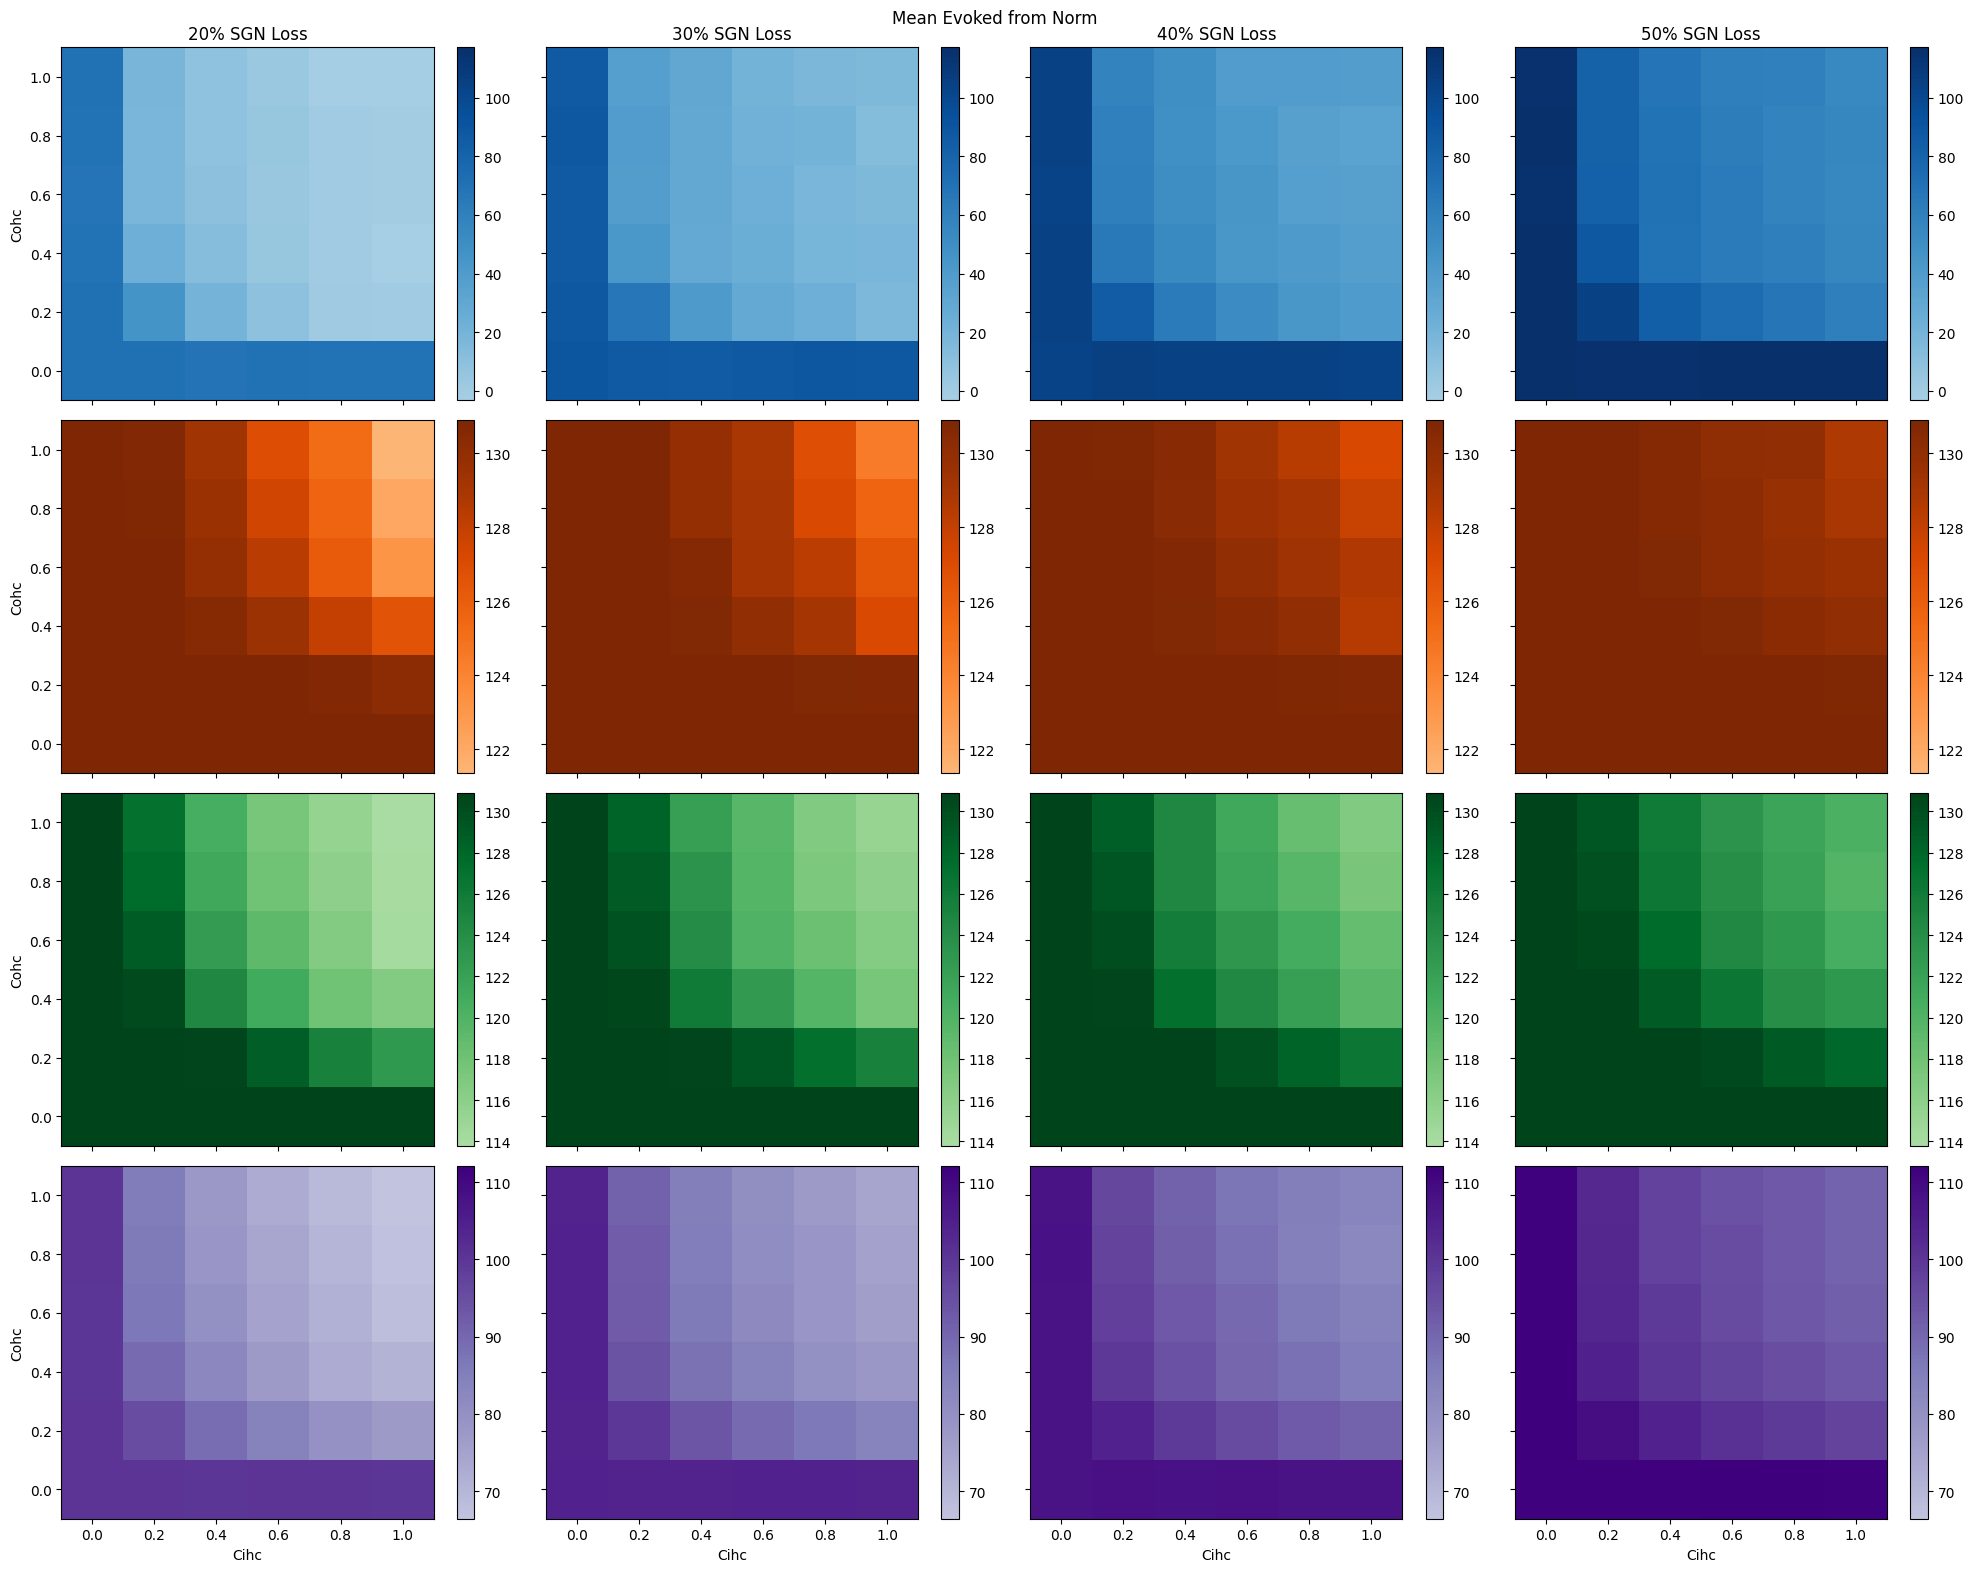

In [14]:
nrows = len(cell_types)
ncols = len(sgn_losses)
fig, axs = plt.subplots(nrows, ncols, figsize=(5*ncols,4*nrows), sharex=True, sharey=True)

measure = evoked_means_from_norm

cell_maxes = {}
cell_mins = {}
for cell_type in cell_types:
    cell_max = []
    cell_min = []
    for sgn_loss in sgn_losses:
        cell_max.append(np.max(measure[sgn_loss][cell_type]))
        cell_min.append(np.min(measure[sgn_loss][cell_type]))
    cell_maxes[cell_type] = np.max(cell_max)
    cell_mins[cell_type] = np.min(cell_min)
    

for col, sgn_loss in enumerate(sgn_losses):      

    for row, cell_type in enumerate(cell_types):

        pc = axs[row,col].pcolormesh(cihcs, cohcs, measure[sgn_loss][cell_type], cmap=cmaps[cell_type], vmax=cell_maxes[cell_type], vmin=cell_mins[cell_type])
        fig.colorbar(pc, ax=axs[row,col])
        

for i in range(nrows):
    axs[i,0].set_ylabel('Cohc')

for i in range(ncols):
    axs[0,i].set_title(f'{sgn_losses[i]}% SGN Loss')
    axs[-1,i].set_xlabel('Cihc')
    axs[-1,i].set_xlabel('Cihc')


# fig.suptitle('Mean Difference (evoked - spontaneous)')
fig.suptitle('Mean Evoked from Norm')
# fig.suptitle('Median Evoked')
fig.tight_layout()

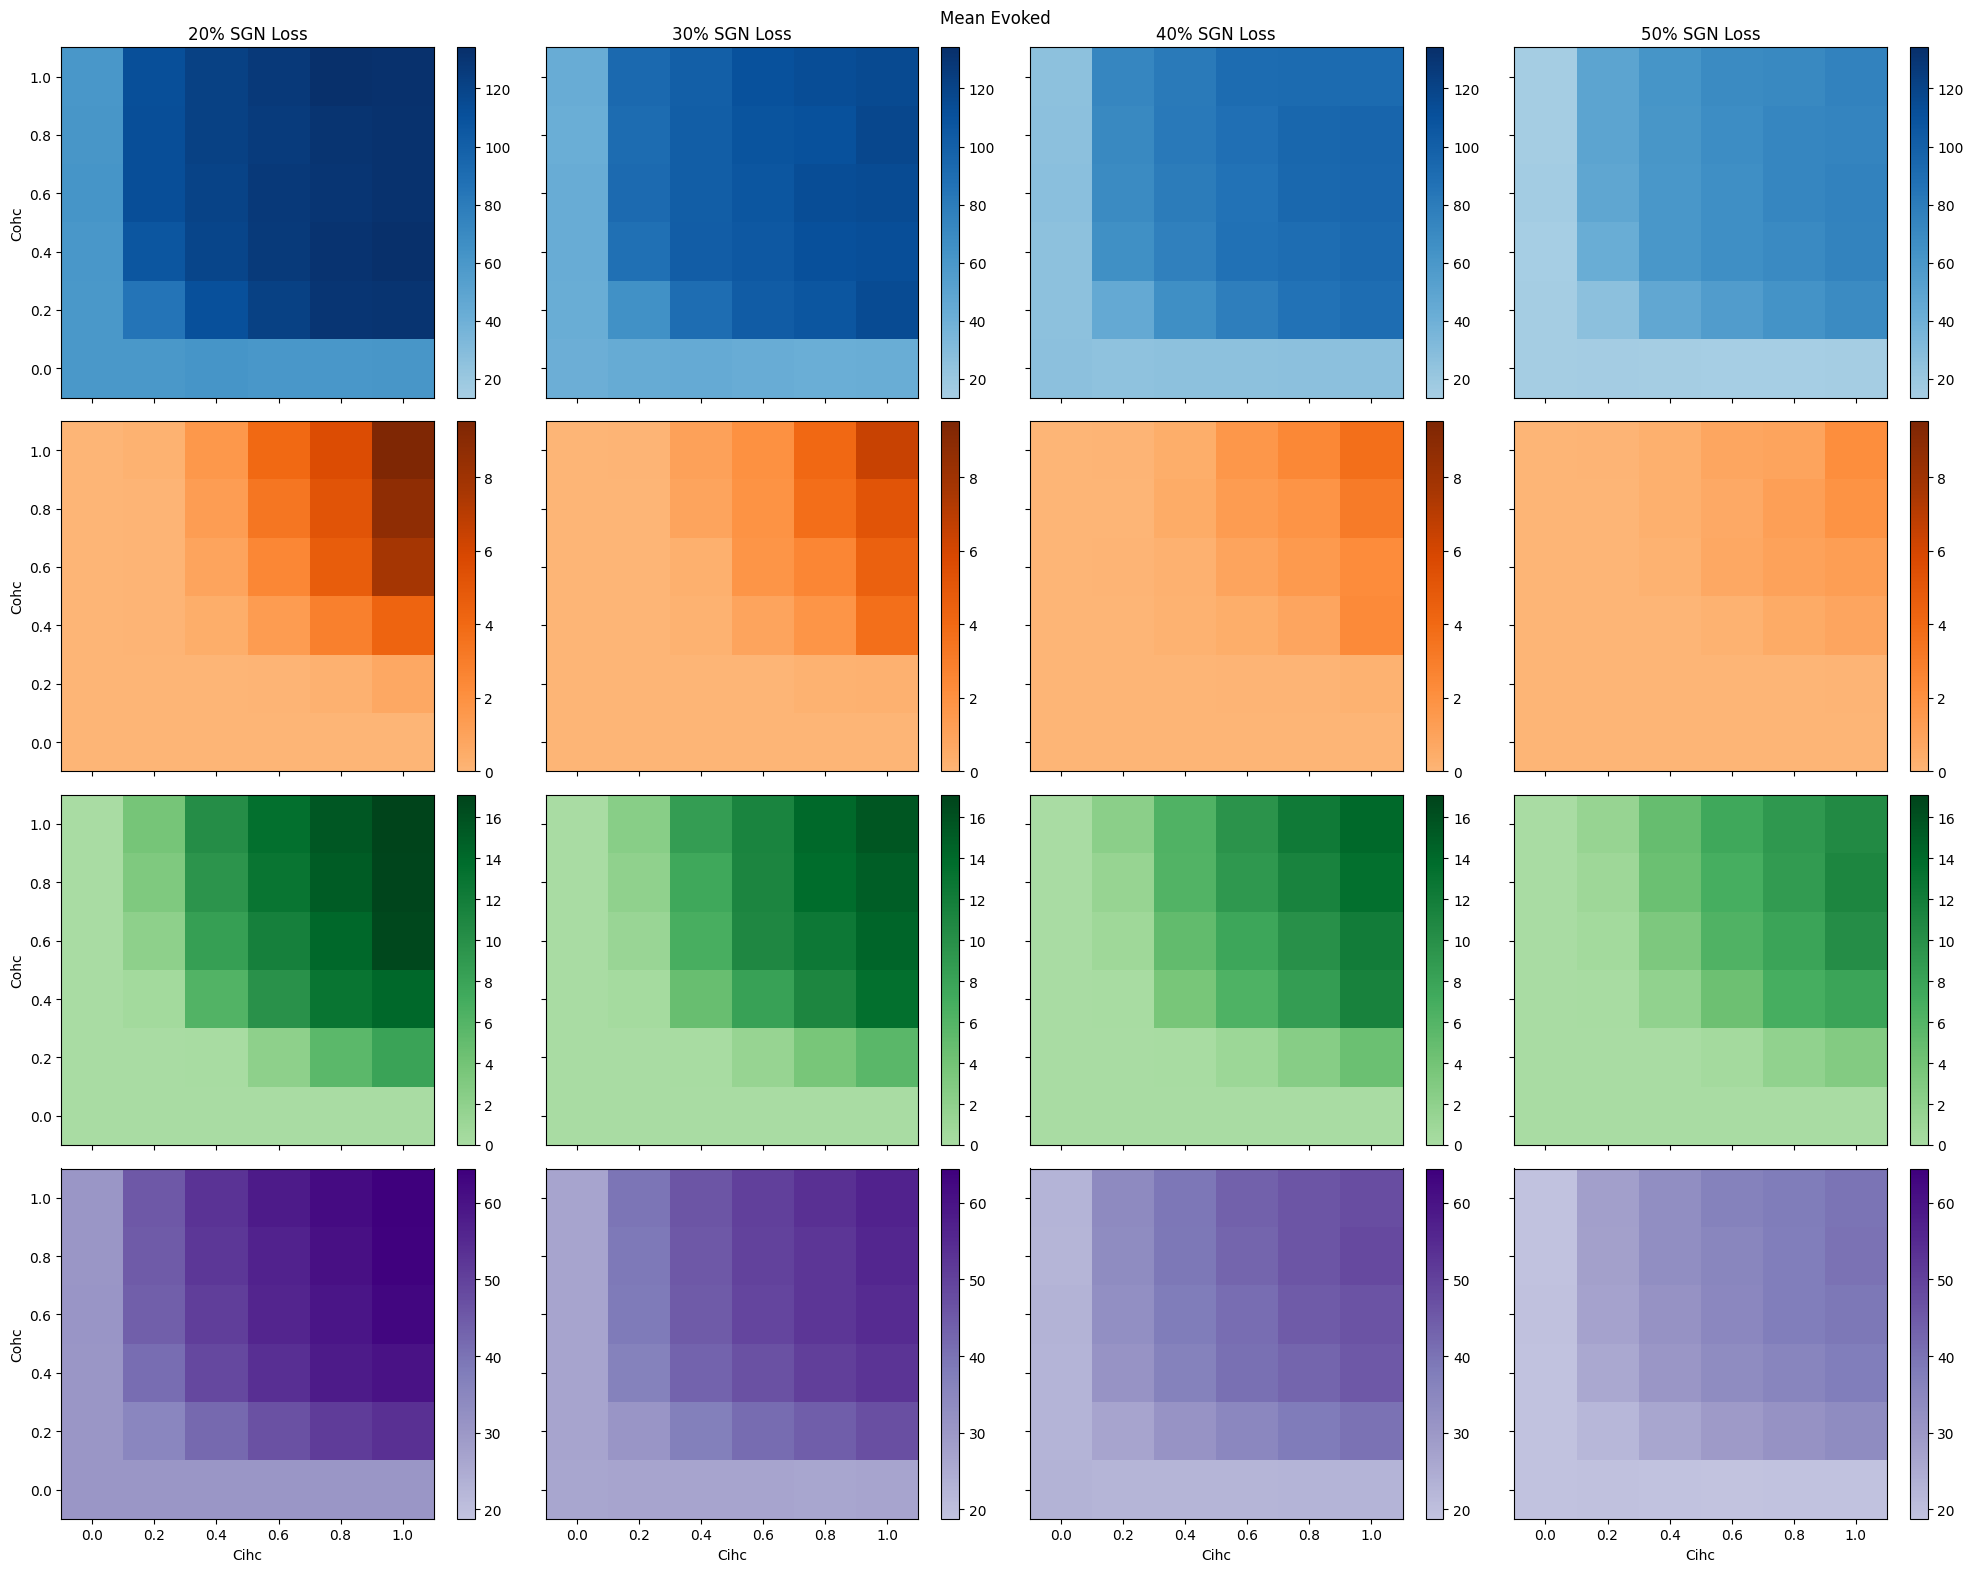

In [15]:
nrows = len(cell_types)
ncols = len(sgn_losses)
fig, axs = plt.subplots(nrows, ncols, figsize=(5*ncols,4*nrows), sharex=True, sharey=True)

measure = evoked_means

cell_maxes = {}
cell_mins = {}
for cell_type in cell_types:
    cell_max = []
    cell_min = []
    for sgn_loss in sgn_losses:
        cell_max.append(np.max(measure[sgn_loss][cell_type]))
        cell_min.append(np.min(measure[sgn_loss][cell_type]))
    cell_maxes[cell_type] = np.max(cell_max)
    cell_mins[cell_type] = np.min(cell_min)
    

for col, sgn_loss in enumerate(sgn_losses):      

    for row, cell_type in enumerate(cell_types):

        pc = axs[row,col].pcolormesh(cihcs, cohcs, measure[sgn_loss][cell_type], cmap=cmaps[cell_type], vmax=cell_maxes[cell_type], vmin=cell_mins[cell_type])
        fig.colorbar(pc, ax=axs[row,col])
        

for i in range(nrows):
    axs[i,0].set_ylabel('Cohc')

for i in range(ncols):
    axs[0,i].set_title(f'{sgn_losses[i]}% SGN Loss')
    axs[-1,i].set_xlabel('Cihc')
    axs[-1,i].set_xlabel('Cihc')


# fig.suptitle('Mean Difference (evoked - spontaneous)')
fig.suptitle('Mean Evoked')
# fig.suptitle('Median Evoked')
fig.tight_layout()
fig.savefig('PCA-hearing_tuning-mean_evoked.png', bbox_inches='tight', dpi=300)
fig.savefig('PCA-hearing_tuning-mean_evoked.pdf', bbox_inches='tight', dpi=300)

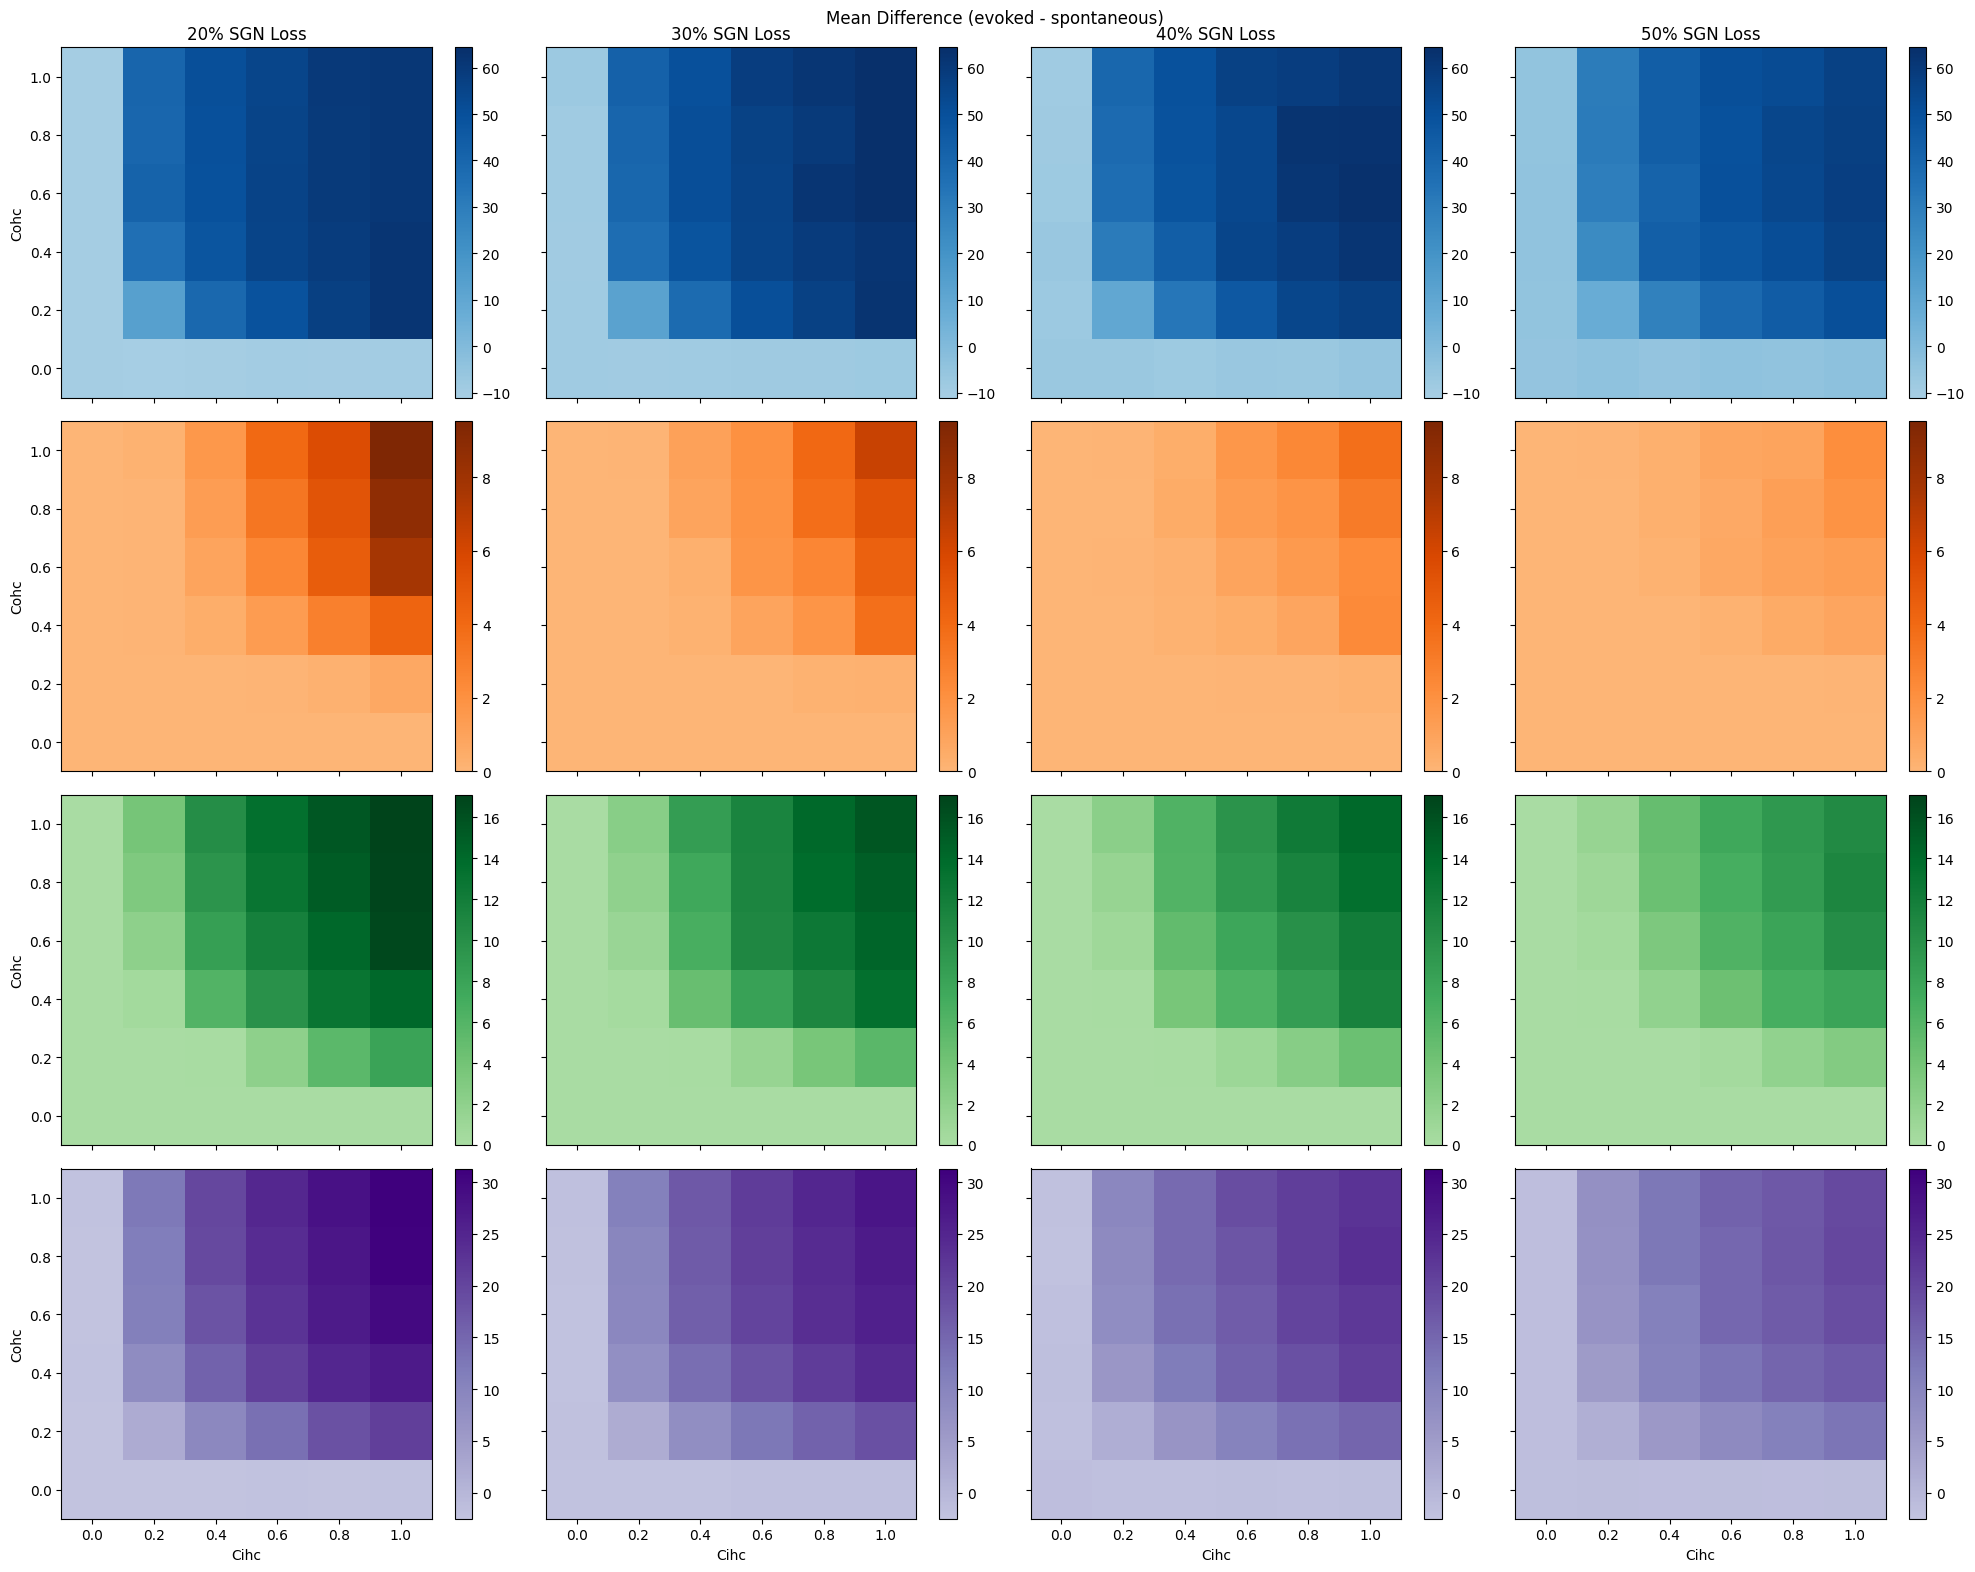

In [16]:
nrows = len(cell_types)
ncols = len(sgn_losses)
fig, axs = plt.subplots(nrows, ncols, figsize=(5*ncols,4*nrows), sharex=True, sharey=True)

measure = diff_means

cell_maxes = {}
cell_mins = {}
for cell_type in cell_types:
    cell_max = []
    cell_min = []
    for sgn_loss in sgn_losses:
        cell_max.append(np.max(measure[sgn_loss][cell_type]))
        cell_min.append(np.min(measure[sgn_loss][cell_type]))
    cell_maxes[cell_type] = np.max(cell_max)
    cell_mins[cell_type] = np.min(cell_min)
    

for col, sgn_loss in enumerate(sgn_losses):      

    for row, cell_type in enumerate(cell_types):

        pc = axs[row,col].pcolormesh(cihcs, cohcs, measure[sgn_loss][cell_type], cmap=cmaps[cell_type], vmax=cell_maxes[cell_type], vmin=cell_mins[cell_type])
        fig.colorbar(pc, ax=axs[row,col])
        

for i in range(nrows):
    axs[i,0].set_ylabel('Cohc')

for i in range(ncols):
    axs[0,i].set_title(f'{sgn_losses[i]}% SGN Loss')
    axs[-1,i].set_xlabel('Cihc')
    axs[-1,i].set_xlabel('Cihc')


fig.suptitle('Mean Difference (evoked - spontaneous)')
# fig.suptitle('Mean Evoked')
# fig.suptitle('Median Evoked')
fig.tight_layout()

In [ ]:
spont_means = {cell_type: np.ones((len(cohcs), len(cihcs))) for cell_type in cell_types}
diff_means = {cell_type: np.ones((len(cohcs), len(cihcs))) for cell_type in cell_types}
evoked_means = {cell_type: np.ones((len(cohcs), len(cihcs))) for cell_type in cell_types}
evoked_medians = {cell_type: np.ones((len(cohcs), len(cihcs))) for cell_type in cell_types}
evoked_maxes = {cell_type: np.ones((len(cohcs), len(cihcs))) for cell_type in cell_types}
fracs_above_spont = {cell_type: np.ones((len(cohcs), len(cihcs))) for cell_type in cell_types}

mean_spont = np.mean(data_frs['spont_rates'][cell_type][1][(freq,level)])
mean_diff = np.mean(data_frs['evoked_rates'][cell_type][1][(freq,level)] - data_frs['spont_rates'][cell_type][1][(freq,level)])
mean_evoked = np.mean(data_frs['evoked_rates'][cell_type][1][(freq,level)])
median_evoked = np.median(data_frs['evoked_rates'][cell_type][1][(freq,level)])
max_evoked = np.max(data_frs['evoked_rates'][cell_type][1][(freq,level)])
frac_above_spont = len(np.where(data_frs['evoked_rates'][cell_type][1][(freq,level)] > mean_spont)[0]) / len(data_frs['evoked_rates'][cell_type][1][(freq,level)])

spont_means[cell_type][r_i, c_i] = mean_spont
diff_means[cell_type][r_i, c_i] = mean_diff
evoked_means[cell_type][r_i, c_i] = mean_evoked
evoked_medians[cell_type][r_i, c_i] = median_evoked
evoked_maxes[cell_type][r_i, c_i] = max_evoked
fracs_above_spont[cell_type][r_i, c_i] = frac_above_spont